# Watanabe-Mualem 
Author: Olaf Cirpka  
References: 
- Watanabe and Flury, 2013
- Mualem, 1976

In [1]:
import sys
sys.path.append('../../')
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

from scipy.integrate import cumulative_trapezoid, simpson 
import matplotlib.pyplot as plt
import utils.petrophysics_capillaryBundles as petro
import utils.petrophysic as petro_par


In [2]:
# definition of van-Genuchten parameters for a silty loam
alpha = 1.6
N     = 1.37
Theta_r = 0.034
Theta_s = 0.46

In [3]:

# test with very fine resolution for integration
S = jnp.geomspace(1e-6,1-1e-6,int(1e6))
hc = petro.h_from_S(S,alpha,N) # m
T = jnp.array([-0.5]) # K

Se = petro.S_from_h(hc,alpha,N)
R = petro.R_from_S(Se,alpha,N)
ri_list = petro.r_i(R,T)
Se_l, Se_i = petro.S_e_unfrozen(Se, ri_list, R)

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


In [4]:
# relative permeability for the Watanabe-Mualem model
krel = petro.k_rel_Mualem(Se, Se_l, R, ri_list, N)

# same thing without ice
krel_noice = petro.k_rel_Mualem(Se, jnp.array([Se]), R,jnp.array([0*ri_list[0,:]]), N)

# relative permeability for the original Watanabe-Flury (Burdine) model
krel2 = petro.k_rel_Burdine(Se, jnp.array([Se_l[0,:]]), R,jnp.array([ri_list[0,:]]),N)

# same thing without ice
krel2_noice = petro.k_rel_Burdine(Se, jnp.array([Se]), R, jnp.array([ri_list[0,:]*0]),N)

krel_vG = Se**0.5 * (1-(1-Se**(N/(N-1)))**((N-1)/N))**2

#########################################################################################
theta = Se*(Theta_s-Theta_r)+Theta_r
theta_i, theta_l = petro_par.phase_separation(theta, Theta_r, T)

Se_drying = (theta_l-Theta_r)/(Theta_s-Theta_r)

krel_drying = petro_par.relperm(Se_drying,N)
krel_imp_50 = petro_par.relperm(Se,N)*petro_par.impedance_factor(theta_i, Omega=50)
krel_imp_10 = petro_par.relperm(Se,N)*petro_par.impedance_factor(theta_i, Omega=10)

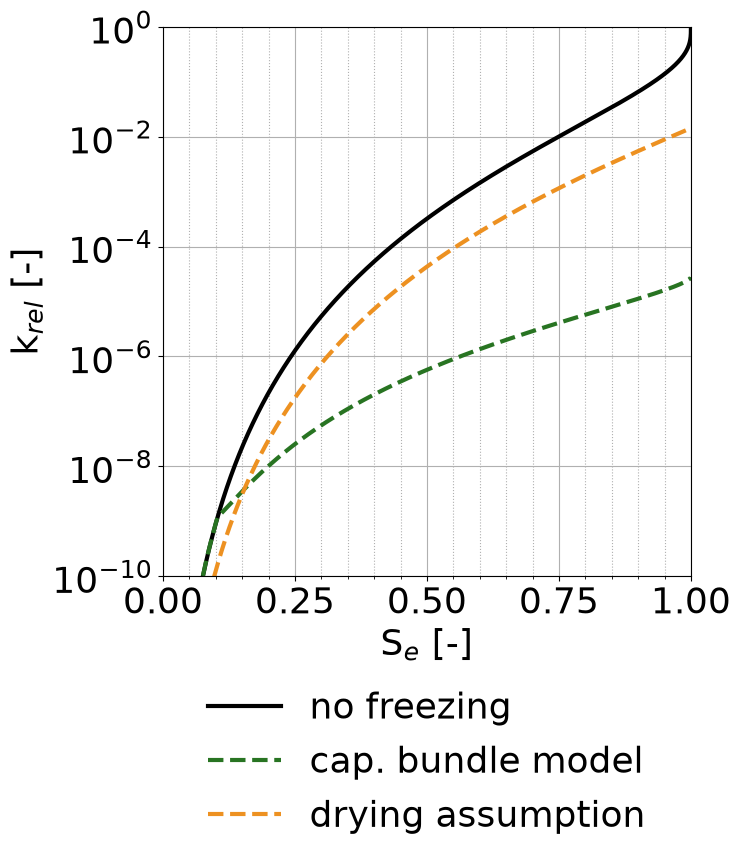

In [5]:
cm = 1/2.54
cobalt=(237/255,145/255,33/255)
green = (40/255,116/255,34/255)
blue = (0/255, 71/255, 171/255)

# set figure text size to 16
plt.rcParams.update({'font.size': 26})
fig, ax = plt.subplots(figsize=(20*cm,24*cm))
ax.semilogy(Se,krel_vG,'k-',linewidth = 3, label='no freezing')
ax.semilogy(Se,krel[0,:],'--',linewidth = 3,color = green,label='cap. bundle model')
#ax.plot(Se,krel_noice[0,:],'k:',label='without ice')
# ax.semilogy(Se,krel2[0,:],':',linewidth = 3,color = green,label=r'Burdine')
#ax.plot(Se,krel2_noice[0,:],'b:',label='W&F without ice')
ax.semilogy(Se,krel_drying,"--",linewidth = 3,color = cobalt,label="drying assumption")
# ax.semilogy(Se,krel_imp_50,"--",linewidth = 3,color = blue,label=r"impedance")
# ax.semilogy(Se,krel_imp_10,"-.",linewidth = 3,color = green,label=r"imp. $\Omega$=10")
ax.legend(loc='upper center',
          bbox_to_anchor=(0.5, -0.15),
          ncol=1,
          frameon=False)
ax.set_ylim(1e-10,1)
ax.set_xlim(0,1)
ax.minorticks_on()
ax.grid(True,'major')
ax.grid(True,which='minor', linestyle=':')
ax.set_xlabel('S$_e$ [-]')
ax.set_ylabel('k$_{rel}$ [-]')
fig.tight_layout()
fig.savefig("graphicalAbstract_relperm.png", dpi = 300, transparent=True)